## Phenology Dev
Develop methods for calculating various phenology from SNOTEL

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel
from pathlib import Path

import os
from dotenv import load_dotenv
load_dotenv(Path.cwd().parents[0] / ".env")

True

### Load a test site
Some recommended sites
- Cumbres Trestle: Lots of missing years
- Garita Peak: has 11 day gap after melt out one year

In [2]:
site = 'Red Mountain Pass'
snotel_path = os.getenv('SNOTEL_PATH')

In [3]:
snotel = PNNLSnotel(site, snotel_path)
snotel.load_data()

In [4]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1980-07-17 00:00:00-06:00,NaN,NaN,NaN,NaN,NaN
1980-07-18 00:00:00-06:00,NaN,NaN,NaN,NaN,NaN
1980-07-19 00:00:00-06:00,NaN,NaN,NaN,NaN,NaN
1980-07-20 00:00:00-06:00,NaN,NaN,NaN,NaN,NaN
1980-07-21 00:00:00-06:00,NaN,NaN,NaN,NaN,NaN


<Axes: xlabel='Date'>

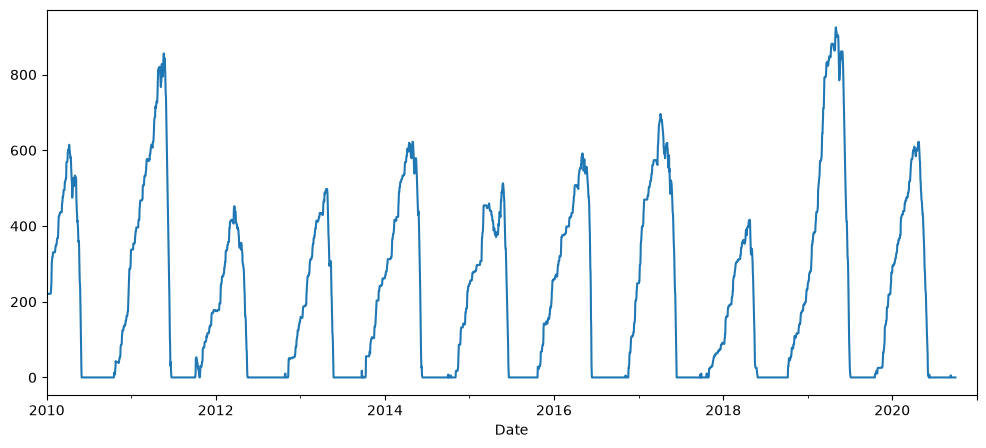

In [5]:
# Initial plot of swe
plt.figure(figsize=(12, 5))
snotel.data.loc['2010':'2020','swe_mm'].plot()

### Snow days per water year

Season length is calculated as "snow days": the count of days with `swe_mm` above a threshold within
the snow-relevant window of each water year (Oct 1 - Sep 30, water year labeled by the year containing
Jan-Sep). This avoids needing to detect a single contiguous onset/melt-out span, so it's more robust at
sites with intermittent snowpack.

Missing data is screened per water year, restricted to the plausible snow window (Oct-Jul, excluding
Aug-Sep when SWE is reliably zero). A water year is skipped entirely if either:
- the longest single run of missing days in the window exceeds `MAX_GAP_DAYS`, or
- the total missing days in the window exceed `MAX_GAP_FRACTION` of the window length.

Otherwise, short gaps are linearly interpolated (time-based) before counting snow days.

In [6]:
import numpy as np

# Snow days parameters
SWE_THRESHOLD_MM = 5.0      # SWE above this counts as a "snow day"
SNOW_WINDOW_MONTHS = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7]  # Oct-Jul; Aug-Sep excluded (reliably snow-free)
MAX_GAP_DAYS = 10           # longest single missing run that is safe to interpolate unconditionally
MAX_GAP_DAYS_FLAT = 30      # longest gap allowed when it's bounded by below-threshold SWE on both sides
MAX_GAP_FRACTION = 0.10     # total missing days allowed within the window, as a fraction of window length

In [7]:
def compute_snow_days(
    data: pd.DataFrame,
    swe_col: str = 'swe_mm',
    threshold_mm: float = SWE_THRESHOLD_MM,
    window_months: list[int] = SNOW_WINDOW_MONTHS,
    max_gap_days: int = MAX_GAP_DAYS,
    max_gap_days_flat: int = MAX_GAP_DAYS_FLAT,
    max_gap_fraction: float = MAX_GAP_FRACTION,
) -> pd.DataFrame:
    '''
    Compute snow days per water year (Oct 1 - Sep 30) from a daily SWE series.

    A gap is safe to interpolate if it is no longer than max_gap_days, or -- if longer -- it is
    no longer than max_gap_days_flat AND the SWE values immediately bounding the gap are both
    below threshold_mm (i.e. the gap sits in a snow-free stretch rather than spanning an
    accumulation/melt transition). A water year is skipped (valid=False, snow_days=NaN) if any
    gap fails both checks, or if total missing days in the window exceed max_gap_fraction of the
    window length. Otherwise gaps are linearly interpolated (time-based) before counting days
    with swe_col > threshold_mm.

    Returns a DataFrame indexed by water_year with columns: valid, snow_days, max_gap_days,
    missing_frac, n_window_days.
    '''
    full_swe = data[swe_col]
    df = data[[swe_col]].copy()
    df['water_year'] = np.where(df.index.month >= 10, df.index.year + 1, df.index.year)
    in_window = df.index.month.isin(window_months)

    records = []
    for wy, group in df[in_window].groupby('water_year'):
        n_window = len(group)
        swe = group[swe_col]
        is_missing = swe.isna()
        total_missing = int(is_missing.sum())
        missing_frac = total_missing / n_window

        longest_gap = 0
        gaps_ok = True
        if is_missing.any():
            run_id = (is_missing != is_missing.shift()).cumsum()
            for _, run_index in is_missing[is_missing].groupby(run_id[is_missing]).groups.items():
                gap_len = len(run_index)
                longest_gap = max(longest_gap, gap_len)

                if gap_len <= max_gap_days:
                    continue

                # Longer gap: only acceptable if bounded by below-threshold SWE on both sides
                start_pos = full_swe.index.get_loc(run_index.min())
                end_pos = full_swe.index.get_loc(run_index.max())
                before_val = full_swe.iloc[start_pos - 1] if start_pos > 0 else np.nan
                after_val = full_swe.iloc[end_pos + 1] if end_pos + 1 < len(full_swe) else np.nan
                flat_bounded = (
                    pd.notna(before_val) and pd.notna(after_val)
                    and before_val <= threshold_mm and after_val <= threshold_mm
                )

                if gap_len > max_gap_days_flat or not flat_bounded:
                    gaps_ok = False
                    break

        valid = gaps_ok and (missing_frac <= max_gap_fraction)

        snow_days = np.nan
        if valid:
            interpolated = swe.interpolate(method='time', limit=max_gap_days_flat, limit_area='inside')
            snow_days = int((interpolated > threshold_mm).sum())

        records.append({
            'water_year': wy,
            'valid': valid,
            'snow_days': snow_days,
            'max_gap_days': longest_gap,
            'missing_frac': missing_frac,
            'n_window_days': n_window,
        })

    return pd.DataFrame(records).set_index('water_year')

In [8]:
snow_day_results = compute_snow_days(snotel.data)

n_valid = snow_day_results['valid'].sum()
n_skipped = (~snow_day_results['valid']).sum()
mean_snow_days = snow_day_results.loc[snow_day_results['valid'], 'snow_days'].mean()

print(f"{site}: {n_valid} valid water years, {n_skipped} skipped")
print(f"Mean snow days per season: {mean_snow_days:.1f}")

snow_day_results

Red Mountain Pass: 35 valid water years, 7 skipped
Mean snow days per season: 229.9


,valid,snow_days,max_gap_days,missing_frac,n_window_days
water_year,,,,,
1980,False,NaN,15,1.0,15
1981,True,229.0,0,0.0,304
1982,True,247.0,0,0.0,304
1983,False,NaN,304,1.0,304
1984,False,NaN,305,1.0,305
1985,True,252.0,0,0.0,304
1986,True,242.0,0,0.0,304
1987,False,NaN,304,1.0,304
1988,True,228.0,0,0.0,305


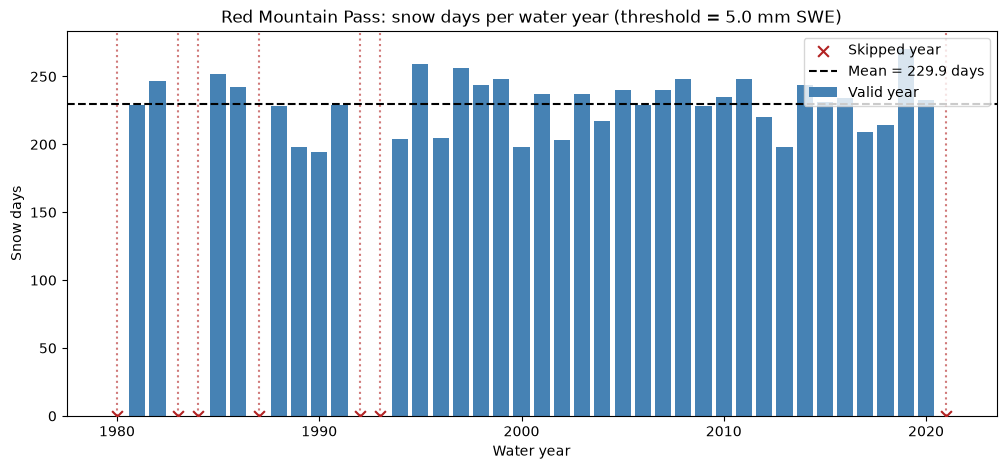

In [9]:
# Plot snow days per water year, marking skipped years and the mean
fig, ax = plt.subplots(figsize=(12, 5))

valid = snow_day_results[snow_day_results['valid']]
skipped = snow_day_results[~snow_day_results['valid']]

ax.bar(valid.index, valid['snow_days'], color='steelblue', label='Valid year')
ax.bar(skipped.index, [0] * len(skipped), color='none')  # keep x-axis ticks for skipped years
for wy in skipped.index:
    ax.axvline(wy, color='firebrick', linestyle=':', alpha=0.6)
ax.scatter(skipped.index, [0] * len(skipped), color='firebrick', marker='x', s=60, label='Skipped year', zorder=3)

ax.axhline(mean_snow_days, color='black', linestyle='--', label=f'Mean = {mean_snow_days:.1f} days')
ax.set_xlabel('Water year')
ax.set_ylabel('Snow days')
ax.set_title(f'{site}: snow days per water year (threshold = {SWE_THRESHOLD_MM} mm SWE)')
ax.legend()
plt.show()

### Melt Season
Evaluate some different options for assessing melt season length.

1. Best fit sigmoid adapted from Hao et al. 2023:
$$ SWE^{DOY}=a + \frac{b}{1+e^{c\cdot(DOY-d)}}$$

2. Simple peak to zero


In [10]:
# Water Year of Interest
WATERYEAR = 2017


In [11]:
from scipy.optimize import curve_fit

In [12]:
# Sigmoid
# Melt season metrics following Hao et. al 2023

FIT_MONTHS = (2, 8)          # Feb-Aug, per Hao et al. 2023
MELT_ONSET_FRACTION = 0.99   # onset = DOY where the fit has declined to 99% of its range from the early-season plateau
MELT_END_THRESHOLD_MM = 10.0 # SWE analog of Hao et al.'s fSCA > 0.05; 1cm is ~the input data's resolution
MELT_END_MIN_RUN_DAYS = 5    # end = last day of the last run of >= 5 consecutive days above threshold

def sigmoid_swe(doy, a, b, c, d):
    return a + b / (1 + np.exp(c * (doy - d)))

def sigmoid_onset_doy(params: dict, fraction: float = MELT_ONSET_FRACTION) -> float:
    '''DOY where the fitted sigmoid has declined to `fraction` of its range from the early-season plateau.'''
    return params['d'] + np.log((1 - fraction) / fraction) / params['c']

def find_melt_end_date(data: pd.DataFrame, water_year: int, swe_col: str = 'swe_mm',
                        threshold_mm: float = MELT_END_THRESHOLD_MM,
                        min_run_days: int = MELT_END_MIN_RUN_DAYS) -> pd.Timestamp:
    '''
    Last day of the last run of >= min_run_days consecutive days with SWE > threshold_mm within
    the water year (Oct 1 - Sep 30). SWE analog of Hao et al.'s "last block of 5 days with
    fSCA > 0.05" melt-end rule. Uses raw (non-gap-filled) observations.
    '''
    water_year_labels = np.where(data.index.month >= 10, data.index.year + 1, data.index.year)
    series = data.loc[water_year_labels == water_year, swe_col]

    above = series > threshold_mm
    run_id = (above != above.shift()).cumsum()
    qualifying_runs = [
        idx for _, idx in above[above].groupby(run_id[above]).groups.items()
        if len(idx) >= min_run_days
    ]

    if not qualifying_runs:
        return pd.NaT

    return qualifying_runs[-1].max()

def fit_melt_sigmoid(data: pd.DataFrame, water_year: int, swe_col: str = 'swe_mm',
                      fit_months: tuple[int, int] = FIT_MONTHS) -> dict:
    '''
    Fit the Hao et al. (2023) sigmoid to SWE over a water year's Feb-Aug window, and derive melt
    onset/end dates and melt season length from it.

    Onset: DOY where the fit has declined to MELT_ONSET_FRACTION of its range from the
    early-season plateau (Hao et al.'s 99%-of-range rule).
    End: last day of the last run of >= MELT_END_MIN_RUN_DAYS consecutive observed days with
    SWE > MELT_END_THRESHOLD_MM (SWE analog of Hao et al.'s fSCA > 0.05 rule), taken from the
    raw data rather than the fit.

    Returns a dict with the fitted params (a, b, c, d), the DOY/SWE arrays used for the fit,
    R^2 of the fit, melt_onset_doy, melt_end_date, melt_end_doy, and melt_season_length.
    '''
    water_year_labels = np.where(data.index.month >= 10, data.index.year + 1, data.index.year)
    in_water_year = water_year_labels == water_year
    in_fit_months = data.index.month.isin(range(fit_months[0], fit_months[1] + 1))
    window = data.loc[in_water_year & in_fit_months, swe_col].dropna()

    if window.empty:
        raise ValueError(f"No SWE data available for water year {water_year} in the fit window.")

    doy = window.index.dayofyear.to_numpy(dtype=float)
    swe = window.to_numpy(dtype=float)

    # Initial guesses: a = late-season baseline, b = amplitude, c = mild positive slope,
    # d = DOY nearest the midpoint between the max and min SWE in the window
    a0 = swe.min()
    b0 = swe.max() - swe.min()
    c0 = 0.1
    d0 = doy[np.argmin(np.abs(swe - (a0 + b0 / 2)))]

    popt, _ = curve_fit(sigmoid_swe, doy, swe, p0=[a0, b0, c0, d0], maxfev=10000)

    fitted = sigmoid_swe(doy, *popt)
    ss_res = np.sum((swe - fitted) ** 2)
    ss_tot = np.sum((swe - swe.mean()) ** 2)
    r_squared = 1 - ss_res / ss_tot

    params = dict(zip('abcd', popt))
    onset_doy = sigmoid_onset_doy(params)
    end_date = find_melt_end_date(data, water_year, swe_col)
    end_doy = end_date.dayofyear if pd.notna(end_date) else np.nan
    season_length = end_doy - onset_doy if pd.notna(end_date) else np.nan

    return {
        'water_year': water_year,
        'params': params,
        'doy': doy,
        'swe': swe,
        'r_squared': r_squared,
        'melt_onset_doy': onset_doy,
        'melt_end_date': end_date,
        'melt_end_doy': end_doy,
        'melt_season_length': season_length,
    }

melt_fit = fit_melt_sigmoid(snotel.data, water_year=WATERYEAR)
print(f"WY{melt_fit['water_year']} fit params: "
      + ", ".join(f"{k}={v:.2f}" for k, v in melt_fit['params'].items()))
print(f"R^2 = {melt_fit['r_squared']:.4f}")
print(f"Melt onset DOY = {melt_fit['melt_onset_doy']:.1f}")
if pd.notna(melt_fit['melt_end_date']):
    print(f"Melt end date = {melt_fit['melt_end_date'].date()} (DOY {melt_fit['melt_end_doy']})")
    print(f"Melt season length = {melt_fit['melt_season_length']:.1f} days")
else:
    print("Melt end date = not found (no qualifying run of low-SWE days)")

WY2017 fit params: a=-4.39, b=580.96, c=0.19, d=154.60
R^2 = 0.9722
Melt onset DOY = 130.8
Melt end date = 2017-06-13 (DOY 164)
Melt season length = 33.2 days


In [13]:
# Peak to Zero
# Melt season metrics: simple peak SWE date to first zero-SWE date thereafter

def fit_peak_to_zero(data: pd.DataFrame, water_year: int, swe_col: str = 'swe_mm') -> dict:
    '''
    Melt season via the simplest possible definition: onset is the date of peak SWE within the
    water year, end is the first date after the peak where SWE reaches zero.

    Returns a dict with melt_onset_doy (peak SWE date), peak_swe, melt_end_date, melt_end_doy,
    and melt_season_length.
    '''
    water_year_labels = np.where(data.index.month >= 10, data.index.year + 1, data.index.year)
    series = data.loc[water_year_labels == water_year, swe_col].dropna()

    if series.empty:
        raise ValueError(f"No SWE data available for water year {water_year}.")

    onset_date = series.idxmax()
    onset_doy = onset_date.dayofyear
    peak_swe = series.loc[onset_date]

    after_peak = series.loc[onset_date:]
    zero_days = after_peak[after_peak <= 0]
    end_date = zero_days.index[0] if not zero_days.empty else pd.NaT
    end_doy = end_date.dayofyear if pd.notna(end_date) else np.nan
    season_length = end_doy - onset_doy if pd.notna(end_date) else np.nan

    return {
        'water_year': water_year,
        'melt_onset_doy': onset_doy,
        'peak_swe': peak_swe,
        'melt_end_date': end_date,
        'melt_end_doy': end_doy,
        'melt_season_length': season_length,
    }

peak_to_zero_fit = fit_peak_to_zero(snotel.data, water_year=WATERYEAR)
print(f"WY{peak_to_zero_fit['water_year']} peak SWE = {peak_to_zero_fit['peak_swe']:.1f} mm")
print(f"Melt onset DOY = {peak_to_zero_fit['melt_onset_doy']}")
if pd.notna(peak_to_zero_fit['melt_end_date']):
    print(f"Melt end date = {peak_to_zero_fit['melt_end_date'].date()} (DOY {peak_to_zero_fit['melt_end_doy']})")
    print(f"Melt season length = {peak_to_zero_fit['melt_season_length']:.1f} days")
else:
    print("Melt end date = not found (SWE never reaches zero after the peak)")

WY2017 peak SWE = 696.0 mm
Melt onset DOY = 95
Melt end date = 2017-06-14 (DOY 165)
Melt season length = 70.0 days


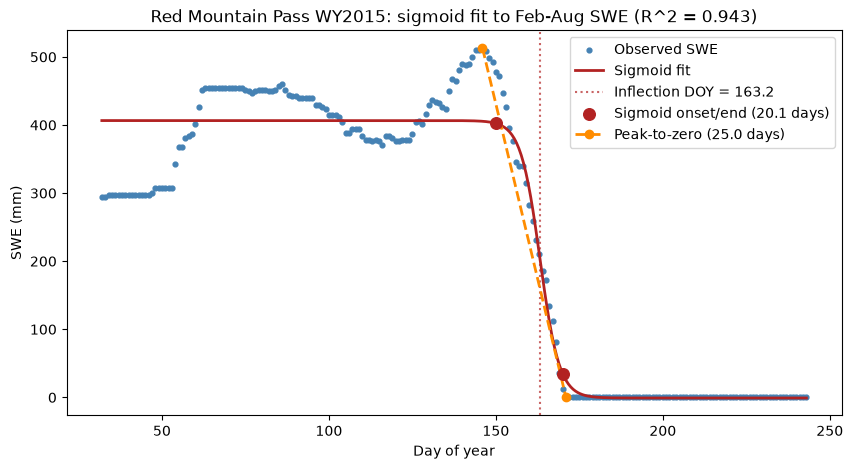

In [14]:
# Visualize observed SWE vs. the fitted sigmoid for the Feb-Aug window
doy_smooth = np.linspace(melt_fit['doy'].min(), melt_fit['doy'].max(), 300)
swe_smooth = sigmoid_swe(doy_smooth, *melt_fit['params'].values())

sigmoid_onset_swe = sigmoid_swe(melt_fit['melt_onset_doy'], *melt_fit['params'].values())
sigmoid_end_swe = sigmoid_swe(melt_fit['melt_end_doy'], *melt_fit['params'].values())

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(melt_fit['doy'], melt_fit['swe'], s=12, color='steelblue', label='Observed SWE')
ax.plot(doy_smooth, swe_smooth, color='firebrick', linewidth=2, label='Sigmoid fit')
ax.axvline(melt_fit['params']['d'], color='firebrick', linestyle=':', alpha=0.7,
           label=f"Inflection DOY = {melt_fit['params']['d']:.1f}")
ax.scatter([melt_fit['melt_onset_doy'], melt_fit['melt_end_doy']],
           [sigmoid_onset_swe, sigmoid_end_swe],
           color='firebrick', marker='o', s=70, zorder=4,
           label=f"Sigmoid onset/end ({melt_fit['melt_season_length']:.1f} days)")

ax.plot([peak_to_zero_fit['melt_onset_doy'], peak_to_zero_fit['melt_end_doy']],
        [peak_to_zero_fit['peak_swe'], 0],
        color='darkorange', linewidth=2, linestyle='--', marker='o',
        label=f"Peak-to-zero ({peak_to_zero_fit['melt_season_length']:.1f} days)")

ax.set_xlabel('Day of year')
ax.set_ylabel('SWE (mm)')
ax.set_title(f"{site} WY{melt_fit['water_year']}: sigmoid fit to Feb-Aug SWE (R^2 = {melt_fit['r_squared']:.3f})")
ax.legend()
plt.show()

**Evaluation:** 

- At Quemazon WY2019 (R^2 = 0.970), the fitted sigmoid plateaus a few days before the
observed SWE actually peaks, so the accumulation limb is underestimated just ahead of the transition
(observed peak ~DOY 75 vs. fit plateau ~DOY 92). This is consistent with the SCF-vs-SWE shape concern
raised earlier - the logistic's flat upper asymptote doesn't capture a still-rising accumulation trend
right before melt onset. Need to check how common this is across other sites/years before deciding
whether it needs to be addressed (e.g. narrowing the fit window, or a different functional form).

### Compare to model data

In [ ]:
from model_datasets.output import LM4ModelOutput 

In [ ]:
namelist = 'gbc'
forcing_str = '01011010'
version = '0005'
model = LM4ModelOutput(site=site, forcing_string=forcing_str, namelist=namelist, version=version, spinup=False)
model_snow = model.get_data(['snow','snow_depth'],'land_daily')

In [ ]:
# Remove timezone from snotel index so it plots with model
snotel.data.index = snotel.data.index.tz_localize(None)

In [ ]:
#Comparison plot SNOTEL, model
axs = snotel.data['swe_mm'].plot()
model_snow['snow'].plot(ax=axs)

In [ ]:
plt.close('all')